In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import seaborn as sns

import pyreadr

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

mpl.rcParams["font.family"] = "Arial"

In [2]:
DATAFOLDER = Path("../data")

result = pyreadr.read_r(DATAFOLDER / "study2_ntnu" / "data" / "panas_ntnu.rds")  # also works for RData
df = result[None]  # extract the pandas data frame from the returned dictionary

In [3]:
df

,ID,session,affect_pre,activation_pre,affect_post,activation_post,belief,drug,affect_diff,activation_diff
0,3932,1,3.75,2.75,2.75,3.50,decaf,caffeine,-1.00,0.75
1,3928,1,3.75,2.25,3.50,2.00,decaf,caffeine,-0.25,-0.25
2,3943,1,3.00,2.75,3.00,3.25,decaf,caffeine,0.00,0.50
3,3930,1,3.50,2.00,3.50,2.50,decaf,caffeine,0.00,0.50
4,3909,1,3.75,2.50,4.00,2.50,decaf,caffeine,0.25,0.00
...,...,...,...,...,...,...,...,...,...,...
155,5302,2,4.25,2.50,4.00,2.50,decaf,decaf,-0.25,0.00
156,5323,2,3.25,1.75,2.50,1.75,caffeine,caffeine,-0.75,0.00
157,4204,2,3.75,2.50,3.75,2.25,decaf,decaf,0.00,-0.25
158,4003,2,3.50,2.50,4.00,3.25,caffeine,caffeine,0.50,0.75


In [44]:
panas_uit = DATAFOLDER / "study1_uit" / "data" / "panas_uit.csv"
df = pd.read_csv(panas_uit, sep=";", decimal=",")

In [45]:
df

,ID,session,attentive.x,tired.x,sad.x,satisfied.x,lazy.x,calm.x,happy.x,anxious.x,...,affect.y,activation.y.x,affect.y.x,activation.y.x_t,affect.y.x_t,sugargroup,caffeinegroup,sugarXcaffeine,motivation.y.x,motivation.y.x_t
0,2009,2nd test,3,5,3,3,2,4,3,2,...,51.50,1.25,0.25,3.25,2.25,1,1,1,0,3
1,2009,3rd test,2,5,2,3,1,3,3,2,...,51.75,0.75,0.25,2.75,2.25,0,1,0,1,4
2,2036,2nd test,3,2,1,3,2,3,3,2,...,51.75,0.00,0.00,2.00,2.00,1,0,0,0,3
3,2036,3rd test,3,3,1,3,2,2,3,2,...,51.75,0.50,0.00,2.50,2.00,1,1,1,0,3
4,2054,2nd test,2,1,1,3,1,4,4,1,...,51.50,0.25,-0.25,2.25,1.75,1,1,1,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,9136,3rd test,3,2,2,3,3,4,2,3,...,51.25,0.75,0.25,2.75,2.25,0,0,0,1,4
118,9245,2nd test,3,4,1,2,4,5,3,1,...,51.25,0.00,0.00,2.00,2.00,1,0,0,0,3
119,9245,3rd test,2,4,1,3,3,3,3,1,...,51.75,0.75,0.25,2.75,2.25,1,1,1,1,4
120,9377,2nd test,1,3,1,2,2,3,3,1,...,51.25,0.50,0.00,2.50,2.00,1,1,1,1,4


In [46]:
df.columns

Index(['ID', 'session', 'attentive.x', 'tired.x', 'sad.x', 'satisfied.x',
       'lazy.x', 'calm.x', 'happy.x', 'anxious.x', 'alert.x', 'nervous.x',
       'energetic.x', 'depressed.x', 'tense.x', 'hungry.x', 'motivated.x',
       'activation.x', 'affect.x', 'lastdrinkhoursago',
       'drinkcontainscaffeine', 'drinkcontainssugar', 'beliefPerformanceCOGED',
       'attentive.y', 'tired.y', 'sad.y', 'satisfied.y', 'lazy.y', 'calm.y',
       'happy.y', 'anxious.y', 'alert.y', 'nervous.y', 'energetic.y',
       'depressed.y', 'tense.y', 'hungry.y', 'motivated.y', 'activation.y',
       'affect.y', 'activation.y.x', 'affect.y.x', 'activation.y.x_t',
       'affect.y.x_t', 'sugargroup', 'caffeinegroup', 'sugarXcaffeine',
       'motivation.y.x', 'motivation.y.x_t'],
      dtype='str')

In [47]:
before_cols = ['attentive.x', 'tired.x', 'sad.x', 'satisfied.x',
       'lazy.x', 'calm.x', 'happy.x', 'anxious.x', 'alert.x', 'nervous.x',
       'energetic.x', 'depressed.x', 'tense.x', 'hungry.x', 'motivated.x']


In [48]:

traits = []
for item in before_cols:
    print(item.split(".")[0])
    traits.append(item.split(".")[0])

attentive
tired
sad
satisfied
lazy
calm
happy
anxious
alert
nervous
energetic
depressed
tense
hungry
motivated


In [53]:
for trait in traits:
    diff = df[f"{trait}.x"] - df[f"{trait}.y"]
    print(diff)
    df[f"{trait}_diff"] = diff

0      0
1     -1
2      0
3     -1
4     -1
      ..
117    0
118    0
119   -3
120   -1
121   -1
Length: 122, dtype: int64
0      3
1      2
2      0
3      1
4     -1
      ..
117    1
118    0
119    2
120    0
121    1
Length: 122, dtype: int64
0      2
1      1
2      0
3      0
4      0
      ..
117    0
118    0
119    0
120    0
121    0
Length: 122, dtype: int64
0      1
1      1
2      0
3      0
4      0
      ..
117    0
118    0
119    0
120    0
121    1
Length: 122, dtype: int64
0      0
1     -1
2      0
3      0
4      0
      ..
117    1
118    0
119    2
120    0
121    0
Length: 122, dtype: int64
0      1
1      0
2      0
3     -1
4      0
      ..
117    1
118    0
119    0
120    0
121    0
Length: 122, dtype: int64
0      0
1      0
2      0
3      0
4      2
      ..
117   -1
118    0
119    0
120    0
121    0
Length: 122, dtype: int64
0      1
1      1
2      0
3      0
4      0
      ..
117    0
118    0
119   -1
120    0
121    0
Length: 122, dtype: int64


In [54]:
df.columns

Index(['ID', 'session', 'attentive.x', 'tired.x', 'sad.x', 'satisfied.x',
       'lazy.x', 'calm.x', 'happy.x', 'anxious.x', 'alert.x', 'nervous.x',
       'energetic.x', 'depressed.x', 'tense.x', 'hungry.x', 'motivated.x',
       'activation.x', 'affect.x', 'lastdrinkhoursago',
       'drinkcontainscaffeine', 'drinkcontainssugar', 'beliefPerformanceCOGED',
       'attentive.y', 'tired.y', 'sad.y', 'satisfied.y', 'lazy.y', 'calm.y',
       'happy.y', 'anxious.y', 'alert.y', 'nervous.y', 'energetic.y',
       'depressed.y', 'tense.y', 'hungry.y', 'motivated.y', 'activation.y',
       'affect.y', 'activation.y.x', 'affect.y.x', 'activation.y.x_t',
       'affect.y.x_t', 'sugargroup', 'caffeinegroup', 'sugarXcaffeine',
       'motivation.y.x', 'motivation.y.x_t', 'attentive_diff', 'tired_diff',
       'sad_diff', 'satisfied_diff', 'lazy_diff', 'calm_diff', 'happy_diff',
       'anxious_diff', 'alert_diff', 'nervous_diff', 'energetic_diff',
       'depressed_diff', 'tense_diff', 'hungry_di

In [ ]:
for tr

Explained variance ratio: [2.658 1.821 1.641 1.215 1.097 1.008 0.954 0.832 0.715 0.666 0.632 0.536
 0.523 0.476 0.351]


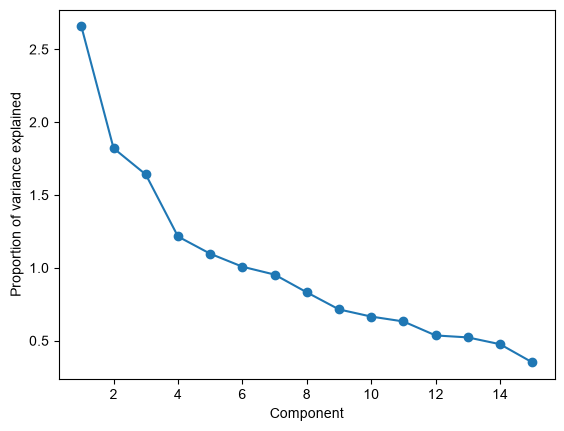

In [55]:
features = ['attentive_diff', 'tired_diff',
       'sad_diff', 'satisfied_diff', 'lazy_diff', 'calm_diff', 'happy_diff',
       'anxious_diff', 'alert_diff', 'nervous_diff', 'energetic_diff',
       'depressed_diff', 'tense_diff', 'hungry_diff', 'motivated_diff']

X = df[features].dropna()
X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
scores = pca.fit_transform(X_scaled)

explained = pca.explained_variance_
print("Explained variance ratio:", explained.round(3))

plt.plot(range(1, len(explained) + 1), explained, marker="o")
plt.xlabel("Component")
plt.ylabel("Proportion of variance explained")
plt.show()

In [56]:
# Loadings: which features drive each component
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f"PC{i+1}" for i in range(len(features))],
)
print(loadings.iloc[:, :3].round(2))

                 PC1   PC2   PC3
attentive_diff  0.38  0.12 -0.03
tired_diff     -0.36  0.38  0.11
sad_diff       -0.08  0.58 -0.16
satisfied_diff  0.31  0.35  0.01
lazy_diff      -0.28  0.10  0.32
calm_diff      -0.14  0.04 -0.27
happy_diff      0.28  0.13 -0.33
anxious_diff    0.09  0.23  0.42
alert_diff      0.37 -0.25  0.05
nervous_diff    0.16  0.19  0.32
energetic_diff  0.39 -0.07 -0.10
depressed_diff  0.11  0.08  0.34
tense_diff      0.21 -0.05  0.39
hungry_diff    -0.03 -0.24  0.34
motivated_diff  0.25  0.36  0.02


In [57]:
# Component scores per row, aligned to the original index
scores_df = pd.DataFrame(scores, index=X.index,
                         columns=[f"PC{i+1}" for i in range(len(features))])

scores_df["sugar"] = df.loc[scores_df.index, "sugargroup"]
scores_df["caffeine"] = df.loc[scores_df.index, "caffeinegroup"]

In [58]:
scores_df.columns

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10',
       'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'sugar', 'caffeine'],
      dtype='str')

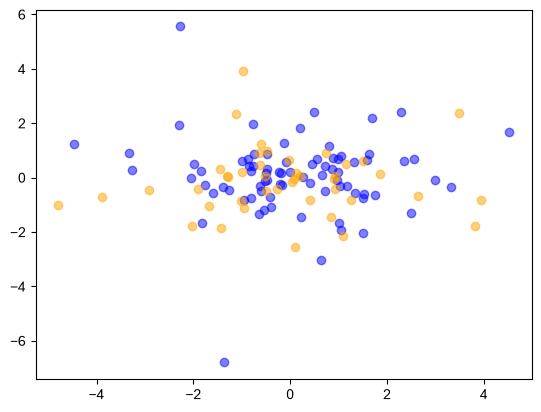

In [59]:
f, ax = plt.subplots()

sugar = scores_df.query("sugar == 1")
no_sugar= scores_df.query("sugar == 0")

ax.scatter(sugar["PC1"], sugar["PC2"], alpha=0.5, color="blue", label="Sugar")
ax.scatter(no_sugar["PC1"], no_sugar["PC2"], alpha=0.5, color="orange", label="No Sugar")

<Axes: xlabel='PC1', ylabel='Density'>

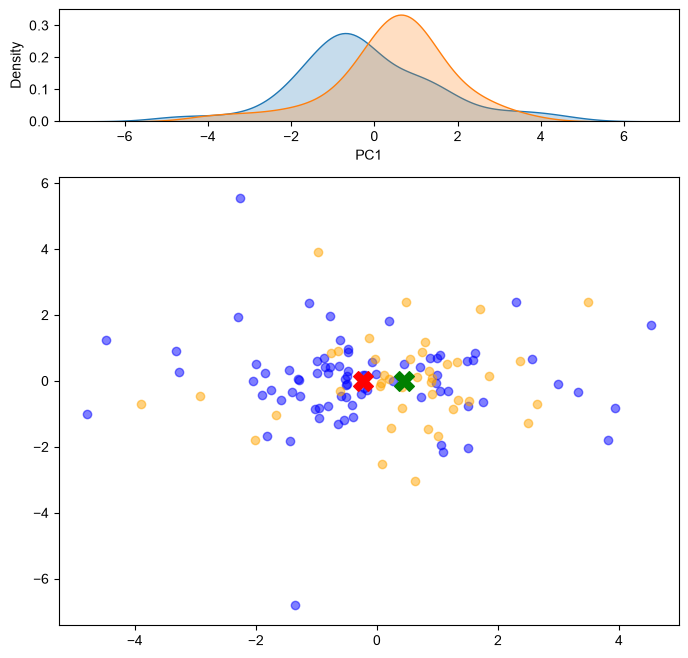

In [67]:
f, [ax1, ax2] = plt.subplots(nrows=2, gridspec_kw={"height_ratios": [0.2, 0.8]}, figsize=(8, 8))

caffeine = scores_df.query("caffeine == 1")
no_caffeine= scores_df.query("caffeine == 0")

ax2.scatter(caffeine["PC1"], caffeine["PC2"], alpha=0.5, color="blue", label="Caffeine")
ax2.scatter(no_caffeine["PC1"], no_caffeine["PC2"], alpha=0.5, color="orange", label="No Caffeine")

ax2.scatter(caffeine["PC1"].mean(), caffeine["PC2"].mean(), color="red", marker="X", s=200, label="Caffeine mean")
ax2.scatter(no_caffeine["PC1"].mean(), no_caffeine["PC2"].mean(), color="green", marker="X", s=200, label="No Caffeine mean")

sns.kdeplot(data=caffeine["PC1"], ax=ax1, fill=True)
sns.kdeplot(data=no_caffeine["PC1"], ax=ax1, fill=True)

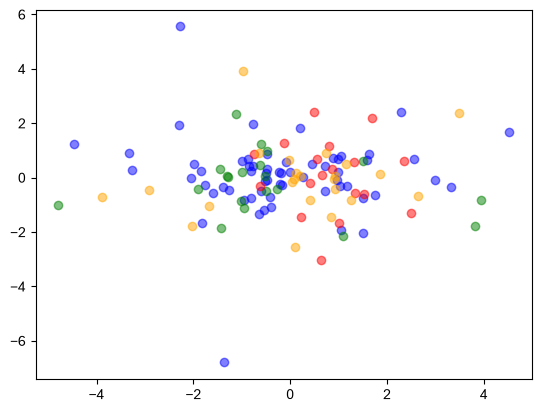

In [64]:
cs = scores_df.query("caffeine == 1 and sugar == 1")
csx = scores_df.query("caffeine == 1 and sugar == 0")
dcs = scores_df.query("caffeine == 0 and sugar == 1")
dcsx = scores_df.query("caffeine == 0 and sugar == 0")

f, ax = plt.subplots()

ax.scatter(cs["PC1"], cs["PC2"], alpha=0.5, color="blue", label="Caffeine and Sugar")
ax.scatter(csx["PC1"], csx["PC2"], alpha=0.5, color="green", label="Caffeine and No Sugar")
ax.scatter(dcs["PC1"], dcs["PC2"], alpha=0.5, color="red", label="No Caffeine and Sugar")
ax.scatter(dcsx["PC1"], dcsx["PC2"], alpha=0.5, color="orange", label="No Caffeine and No Sugar")